# 02 — Metrics

**What do these numbers mean, and what can they not tell you?**

Read this before any experiment. Several of the metrics we rely on answer a
narrower question than their name suggests, and the difference decides
whether a result is real.

| section | |
|---|---|
| 1 | the catalogue — every metric, by the question it answers, and its blind spot |
| 2 | the SLAs — each target, why that number, which metric proves it |
| 3 | percentiles — why histograms, and when a percentile is not trustworthy |
| 4 | component checks — each component judged by its own metrics |
| 5 | watch them move — own seeded load, with the real Grafana panels |

Independent: drives its own load, needs nothing from 01. Just `make ssh`.


In [1]:
%load_ext autoreload
%autoreload 2

import os, sys, time, random
sys.path.insert(0, '..')

from utils import Cluster, Report, filler
from prom import (Prom, Grafana, CATALOGUE, COMPONENT_CHECKS, LATENCY_HISTOGRAMS,
                  panel_id, panel_queries, metric_name, GRAFANA_URL)
from slos import SLOS, TTFT_BUDGET_S, SPEECH_STAGES, budget_rows, table_rows

cluster = Cluster()
prom    = Prom()
grafana = Grafana(password=os.environ.get('GRAFANA_PASSWORD', ''))
report  = Report('Dodona 02 — metrics', 'what the numbers mean')

report.objective(
    'What does each metric mean, what does good look like, and what can it '
    'NOT tell you?',
    falsified_by='a metric in the catalogue that no longer exists, or a trap '
                 'that no longer reproduces')



Objective
  What does each metric mean, what does good look like, and what can it NOT tell you?
  Falsified by: a metric in the catalogue that no longer exists, or a trap that no longer reproduces


Report(title='Dodona 02 — metrics', subtitle='what the numbers mean', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='What does each metric mean, what does good look like, and what can it NOT tell you?', note=''), _Block(kind='text', payload='Falsified by: a metric in the catalogue that no longer exists, or a trap that no longer reproduces', note='')])

## 0. Generate the traffic this notebook reads

First, so every section below reads data from **this run** rather than
whatever the cluster happened to do earlier. 8 short requests and 4 long
**unique** ones — unique matters, because a repeated prompt is served from
decode's own cache and nothing crosses between pods.

Then one scrape interval, so Prometheus has it.


In [2]:
report.heading('0. Traffic for this run')
random.seed(2)

sent, failed = 0, {}
for i in range(8):
    r = cluster.chat('Reply with the single word: ok', max_tokens=8); sent += 1
    if '_error' in r: failed[r['_error']] = failed.get(r['_error'], 0) + 1
for i in range(4):
    r = cluster.chat(f'[{i}-{random.random()}] ' + filler(4000) + '\n\nReply with: ok',
                     max_tokens=8, timeout=180); sent += 1
    if '_error' in r: failed[r['_error']] = failed.get(r['_error'], 0) + 1

time.sleep(20)   # one scrape interval at 15s
report.table(['', 'count'], [['requests sent', sent],
                            *[[f'refused: {k}', n] for k, n in failed.items()]],
             note='Refusals here are gateway decisions, not GPU limits.')
report.verdict(sent - sum(failed.values()) > 0, 'some traffic completed')
report.conclusion(f'{sent} requests, {sum(failed.values())} refused. Every number '
                  'below covers a 15-minute window that includes this traffic.')



0. Traffic for this run


                 count
  -------------  -----
  requests sent     12
  -- Refusals here are gateway decisions, not GPU limits.
  PASS  some traffic completed

  >> 12 requests, 0 refused. Every number below covers a 15-minute window that includes this traffic.



Report(title='Dodona 02 — metrics', subtitle='what the numbers mean', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='What does each metric mean, what does good look like, and what can it NOT tell you?', note=''), _Block(kind='text', payload='Falsified by: a metric in the catalogue that no longer exists, or a trap that no longer reproduces', note=''), _Block(kind='heading', payload='0. Traffic for this run', note=''), _Block(kind='table', payload=(['', 'count'], [['requests sent', 12]]), note='Refusals here are gateway decisions, not GPU limits.'), _Block(kind='verdict', payload=(True, 'some traffic completed'), note=''), _Block(kind='conclusion', payload='12 requests, 0 refused. Every number below covers a 15-minute window that includes this traffic.', note='')])

## 1. The catalogue

Grouped by the **question**, not the metric name. A name tells you nothing
about whether its value is good.

The last column is the one that matters: **what this metric cannot tell you.**
Twenty of the twenty-three carry one.


In [3]:
# metric name first, then the value, then what it means — a reader needs
# to know WHICH series they would go and look at.
for question, entries in CATALOGUE.items():
    report.heading(question)
    rows = []
    for label, expr, means, blind in entries:
        got = prom.query(expr)
        value = f'{got[0][1]:,.4g}' if got else ('—' if not prom.up() else 'no data')
        rows.append([metric_name(expr), value, label, means])
    report.table(['metric', 'now', 'answers', 'means'], rows)
    for label, expr, _, blind in entries:
        if blind:
            report.text(f'{metric_name(expr)} — CANNOT TELL YOU: {blind}')



Is the GPU busy?


  metric                         now  answers                           means                                                            
  --------------------------  ------  --------------------------------  -----------------------------------------------------------------
  vllm:kv_cache_usage_perc    0.1957  How full is the KV cache?         fraction of a pod's own KV in use — the signal kv_threshold reads
  vllm:num_requests_running        0  How many sequences are resident?  requests the scheduler is stepping right now                     
  vllm:num_requests_waiting        0  Is anything queued?               admitted but not yet running — the scheduler is the limiter      
  vllm:num_preemptions_total       0  Did we overcommit?                the engine evicted a running sequence to fit another             
  vllm:kv_cache_usage_perc — CANNOT TELL YOU: it is a RATIO of that slice. 50% of 4.1 GiB is not 50% of the card.
  vllm:num_requests_running — CANNOT TELL YOU: says nothin

  metric                              now      answers                              means                                                   
  ----------------------------------  -------  -----------------------------------  --------------------------------------------------------
  vllm:time_to_first_token_seconds    2.321    Dead air before the answer starts    TTFT p95 — for a voice agent this is silence            
  vllm:time_per_output_token_seconds  no data  How it reads aloud                   ITL — inter-token latency, the cadence of speech        
  vllm:e2e_request_latency_seconds    1.44     The whole request                    E2E p95 — what the caller waits                         
  vllm:request_queue_time_seconds     1.44     Time lost before the GPU touched it  queue p95 — the part admission control is meant to bound
  vllm:time_to_first_token_seconds — CANNOT TELL YOU: a p95 over a 5m window hides a 30s stall that hit three users.
  vllm:time_per_output_token_seconds 

  metric                                                                                        now  answers                          means                                                              
  --------------------------------------------------------------------------------------  ---------  -------------------------------  -------------------------------------------------------------------
  vllm:external_prefix_cache_queries_total{pod=~"vllm-decode.*"}                          9.724e+04  Was the connector asked?         decode looked for blocks on the producer                           
  vllm:external_prefix_cache_hits_total{pod=~"vllm-decode.*"}                             9.656e+04  Did it find blocks?              the LOOKUP matched                                                 
  vllm:prompt_tokens_by_source_total{source="external_kv_transfer",pod=~"vllm-decode.*"}  9.589e+04  Did bytes actually arrive?       prompt tokens whose KV came over the wire instead of being

  metric                  now  answers                means                          
  --------------------  -----  ---------------------  -------------------------------
  orch_requests_total   8,221  How much arrived?      requests past guardrails       
  orch_completed_total  4,159  How much was served?   completions                    
  orch_shed_total         200  How much was refused?  shed, by why                   
  orch_overflow_total       0  Did anything leave?    bursted to an external provider
  orch_shed_total — CANNOT TELL YOU: a 429 is the tenant over quota; a 503 is capacity. Reporting them together makes a quota limit look like a GPU limit.
  orch_overflow_total — CANNOT TELL YOU: capped for the process lifetime, so 0 can mean 'never needed' or 'budget already spent'.

Is routing choosing well?


  metric                              now  answers                     means                                
  --------------------------------  -----  --------------------------  -------------------------------------
  orch_pick_total                   8,318  How many placements?        a pod was chosen                     
  orch_sticky_total                     0  How many were prefix-warm?  placed where the prefix already lives
  orch_pick_unknown_snapshot_total      0  How many were blind?        chosen with no usable signal         
  orch_sticky_total — CANNOT TELL YOU: only meaningful against the total — 10 sticky of 10 is perfect, of 1000 is noise.
  orch_pick_unknown_snapshot_total — CANNOT TELL YOU: high here means the scorers are inert and placement is effectively random, whatever the policy says.

Is the autoscaler awake?


  metric                                                     now  answers              means                      
  ---------------------------------------------------------  ---  -------------------  ---------------------------
  keda_scaler_metrics_value                                    0  What does KEDA see?  the value its trigger reads
  kube_deployment_status_replicas{deployment="vllm-decode"}    1  What has it done?    actual replicas            
  keda_scaler_metrics_value — CANNOT TELL YOU: it polls — it lags the real signal.
  kube_deployment_status_replicas{deployment="vllm-decode"} — CANNOT TELL YOU: scaling UP takes minutes on a pod that loads weights; the metric moves long before capacity does.


## 2. The SLAs

A measurement is a number. A measurement against a promise is a result.

These live in `benchmarking/slos.py`, so every notebook checks the same ones
and nothing drifts between documents.


In [4]:
report.heading('2. The SLAs')
rows = []
for key, s in SLOS.items():
    rows.append([s.label, f'{s.target:g}{s.unit}', s.why])
report.table(['promise', 'target', 'why that number'], rows)
report.text('Concurrency is deliberately absent: it is derived in 03-capacity '
            'from a measured saturation curve. A concurrency target picked '
            'before measuring is a wish.')
report.conclusion(
    'Each has a metric that proves it: TTFT and turn from the latency '
    'histograms, preemptions from vllm:num_preemptions_total, shed rate from '
    'orch_shed_total over orch_requests_total.')



2. The SLAs
  promise                   target  why that number                                                                                                                                                                                                                                                   
  ------------------------  ------  ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
  TTFT p95                  0.8s    A voice agent's latency is dead air, and the listener's 1.5s covers the whole path: ASR, the engine, then TTS. 0.8s is what remains for first token once 0.7s of the rest is paid for.                                                                            
  inter-token latency p95   0.08s   Speech is spoken at 3.3 tokens/s, so past 0.303s per token TTS run

Report(title='Dodona 02 — metrics', subtitle='what the numbers mean', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='What does each metric mean, what does good look like, and what can it NOT tell you?', note=''), _Block(kind='text', payload='Falsified by: a metric in the catalogue that no longer exists, or a trap that no longer reproduces', note=''), _Block(kind='heading', payload='0. Traffic for this run', note=''), _Block(kind='table', payload=(['', 'count'], [['requests sent', 12]]), note='Refusals here are gateway decisions, not GPU limits.'), _Block(kind='verdict', payload=(True, 'some traffic completed'), note=''), _Block(kind='conclusion', payload='12 requests, 0 refused. Every number below covers a 15-minute window that includes this traffic.', note=''), _Block(kind='heading', payload='Is the GPU busy?', note=''), _Block(kind='table', payload=(['metric', 'now', 'answers', 'means'], [['vllm:kv_cache_usage_perc', '0.1957', 'How full is 

## 3. Where the time goes

A request spends its life in three places: **waiting** to be scheduled,
**prefill** turning the prompt into KV, and **decode** emitting tokens.
They should add up to roughly the end-to-end time.

**TTFT** is the one a listener feels — silence before the answer starts.
It gets percentiles because its histogram resolves them; the phase
timings are quoted as exact means.



3. Where the time goes


  stage                    mean       of end-to-end  what happens here        
  -----------------------  ---------  -------------  -------------------------
  waiting to be scheduled  505.0 ms             39%  admitted, not yet running
  prefill                  33.3 ms               3%  the prompt becomes KV    
  decode                   676.9 ms             52%  tokens come out          
  end to end               1303.8 ms           100%  over 8,318 requests      


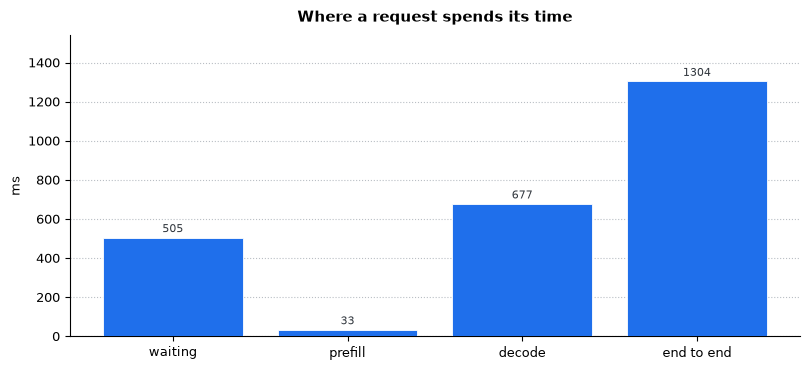

  how to read it: the first three are phases of the fourth


  time to first token  seconds
  -------------------  -------
  p50                    0.175
  p90                    2.159
  p99                    2.466
  mean                   0.627


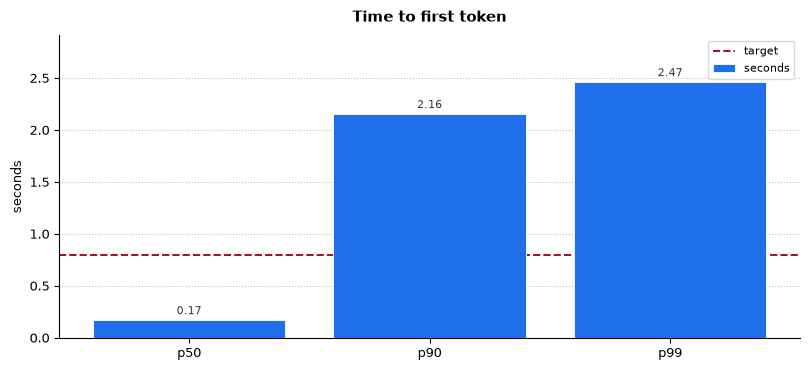

  how to read it: dashed line is the 0.8s engine budget
  MISS  TTFT p95                     2.32931s <= 0.8s
        why it matters: A voice agent's latency is dead air, and the listener's 1.5s covers the whole path: ASR, the engine, then TTS. 0.8s is what remains for first token once 0.7s of the rest is paid for.



  >> A request takes 1304 ms end to end, and decode is the largest share at 52%. The three phases account for 93% of the total; the rest is scheduling overhead. First token lands at 2329 ms p95, which is 2.9x the 0.8s budget — so the engine is outside its share of the speech path. Note where the time goes: prefill is only 3%, so the delay is not the model reading the prompt. It is 39% waiting to be scheduled plus 52% in decode, which on this fleet includes waiting for the KV hop to land.



Report(title='Dodona 02 — metrics', subtitle='what the numbers mean', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='What does each metric mean, what does good look like, and what can it NOT tell you?', note=''), _Block(kind='text', payload='Falsified by: a metric in the catalogue that no longer exists, or a trap that no longer reproduces', note=''), _Block(kind='heading', payload='0. Traffic for this run', note=''), _Block(kind='table', payload=(['', 'count'], [['requests sent', 12]]), note='Refusals here are gateway decisions, not GPU limits.'), _Block(kind='verdict', payload=(True, 'some traffic completed'), note=''), _Block(kind='conclusion', payload='12 requests, 0 refused. Every number below covers a 15-minute window that includes this traffic.', note=''), _Block(kind='heading', payload='Is the GPU busy?', note=''), _Block(kind='table', payload=(['metric', 'now', 'answers', 'means'], [['vllm:kv_cache_usage_perc', '0.1957', 'How full is 

In [5]:
report.heading('3. Where the time goes')

# The exact mean from _sum/_count. For the phase timings this is the
# figure to quote: vLLM 0.31.0 buckets them from 0.3s and nothing here
# gets near that, so their percentiles carry no information.
mean = lambda n: prom.histogram_stats(n).get('mean', 0.0)
e2e, queue = mean('e2e'), mean('queue')
pre, dec   = mean('prefill'), mean('decode')
n_req      = prom.histogram_stats('e2e').get('count', 0)

pct = lambda x: f'{x / e2e:.0%}' if e2e else '—'
report.table(['stage', 'mean', 'of end-to-end', 'what happens here'], [
    ['waiting to be scheduled', f'{queue * 1000:.1f} ms', pct(queue),
     'admitted, not yet running'],
    ['prefill', f'{pre * 1000:.1f} ms', pct(pre), "the prompt becomes KV"],
    ['decode',  f'{dec * 1000:.1f} ms', pct(dec), 'tokens come out'],
    ['end to end', f'{e2e * 1000:.1f} ms', '100%', f'over {n_req:,.0f} requests'],
])

report.bar('Where a request spends its time',
           ['waiting', 'prefill', 'decode', 'end to end'],
           {'milliseconds': [queue * 1000, pre * 1000, dec * 1000, e2e * 1000]},
           ylabel='ms',
           note='the first three are phases of the fourth')

# TTFT is bucketed from 0.001s, so its percentiles are real.
t = prom.quantiles('ttft', qs=(0.5, 0.9, 0.99))
if t:
    report.table(['time to first token', 'seconds'],
                 [['p50', f'{t[0.5]:.3f}'], ['p90', f'{t[0.9]:.3f}'],
                  ['p99', f'{t[0.99]:.3f}'], ['mean', f"{mean('ttft'):.3f}"]])
    report.bar('Time to first token', ['p50', 'p90', 'p99'],
               {'seconds': [t[0.5], t[0.9], t[0.99]]}, ylabel='seconds',
               hline=SLOS['ttft_p95'].target,
               note=f'dashed line is the {TTFT_BUDGET_S:g}s engine budget')
    report.slo('ttft_p95', prom.quantiles('ttft', qs=(0.95,)).get(0.95, 0))

accounted = queue + pre + dec

# Computed, not asserted. This conclusion used to state "prefill is the largest
# share" and "well inside the promise" as fixed prose. Both were true when
# written and both later went false while the sentence kept claiming them —
# beside a verdict line that said MISS. A sentence that does not track the
# numbers above it is worse than no sentence.
phases = {'waiting to be scheduled': queue, 'prefill': pre, 'decode': dec}
biggest = max(phases, key=phases.get)
ttft_p95 = prom.quantiles('ttft', qs=(0.95,)).get(0.95, 0.0)
inside = ttft_p95 <= SLOS['ttft_p95'].target

report.conclusion(
    f'A request takes {e2e*1000:.0f} ms end to end, and {biggest} is the largest '
    f'share at {pct(phases[biggest])}. The three phases account for '
    f'{accounted/e2e:.0%} of the total; the rest is scheduling overhead. '
    + (f'First token lands at {ttft_p95*1000:.0f} ms p95, inside the '
       f'{SLOS["ttft_p95"].target:g}s budget.' if inside else
       f'First token lands at {ttft_p95*1000:.0f} ms p95, which is '
       f'{ttft_p95/SLOS["ttft_p95"].target:.1f}x the {SLOS["ttft_p95"].target:g}s '
       f'budget — so the engine is outside its share of the speech path. '
       f'Note where the time goes: prefill is only {pct(pre)}, so the delay is '
       f'not the model reading the prompt. It is {pct(queue)} waiting to be '
       f'scheduled plus {pct(dec)} in decode, which on this fleet includes '
       f'waiting for the KV hop to land.'))


## 4. Component checks

Each component, its own metrics, and a verdict. First principles: what is
this component supposed to do, which number says whether it did it.

The *cannot tell you* column in section 1 is what keeps these honest — several
of these metrics answer a narrower question than their name suggests.


In [6]:
report.heading('4. Component checks')
v = lambda expr: (prom.query(expr)[0][1] if prom.query(expr) else 0.0)

for group, checks in COMPONENT_CHECKS.items():
    report.heading(group)
    rows = []
    for label, expr, meaning in checks:
        got = prom.query(expr)
        value = f'{got[0][1]:,.4g}' if got else 'no data'
        rows.append([metric_name(expr), value, meaning])
    report.table(['metric', 'value', 'what it means'], rows)



4. Component checks

prefill / decode roles


  metric                                                   value  what it means                            
  ---------------------------------------------------  ---------  -----------------------------------------
  vllm:prompt_tokens_total{pod=~"vllm-prefill.*"}      2.023e+07  prefill should carry prompt work         
  vllm:generation_tokens_total{pod=~"vllm-prefill.*"}      4,159  near 0: its leg is sent with max_tokens=1
  vllm:generation_tokens_total{pod=~"vllm-decode.*"}   7.874e+05  decode does the generating               

scheduler


  metric                       value  what it means                              
  --------------------------  ------  -------------------------------------------
  vllm:num_requests_running        0  in flight on the GPU                       
  vllm:num_requests_waiting        0  queued behind max-num-seqs                 
  vllm:num_preemptions_total       0  must be 0 — a preempt is a stall mid-answer
  vllm:kv_cache_usage_perc    0.1957  the signal admission reads                 

KV hop


  metric                                                                                      value  what it means                            
  --------------------------------------------------------------------------------------  ---------  -----------------------------------------
  vllm:external_prefix_cache_queries_total{pod=~"vllm-decode.*"}                          9.724e+04  decode looked for remote blocks          
  vllm:external_prefix_cache_hits_total{pod=~"vllm-decode.*"}                             9.656e+04  blocks found remotely                    
  vllm:prompt_tokens_by_source_total{source="external_kv_transfer",pod=~"vllm-decode.*"}  9.589e+04  KV that arrived instead of being computed
  vllm:prompt_tokens_by_source_total{source="local_compute",pod=~"vllm-decode.*"}               673  prompt work decode had to do itself      
  orch_kv_transfer_total                                                                      4,159  router bookkeeping — not proof of bytes  

  metric                value  what it means           
  --------------------  -----  ------------------------
  orch_requests_total   8,221  reached the gateway     
  orch_completed_total  4,159  served                  
  orch_shed_total       4,062  refused, by reason below
  orch_overflow_total       0  bursted to a provider   

routing


  metric                            value  what it means                          
  --------------------------------  -----  ---------------------------------------
  orch_pick_total                   8,318  a pod was chosen                       
  orch_sticky_total                     0  placed on a prefix-warm pod            
  orch_pick_unknown_snapshot_total      0  placed blind — the scorer had no signal

KEDA
====


  metric                                                     value  what it means            
  ---------------------------------------------------------  -----  -------------------------
  keda_scaler_metrics_value                                      0  what KEDA sees           
  kube_deployment_status_replicas{deployment="vllm-decode"}      1  what it has done about it


### 4.1 The KV connector

It exists to let decode load the prompt's KV from prefill instead of
recomputing it. Three numbers, in the order the request passes through them:
**asked → found → arrived.**

`external_prefix_cache_hits_total` records that the *lookup* matched. The
pull happens after, and can fail. So `found` and `arrived` agreeing is what
says the connector is doing its job end to end.



4.1 The KV connector


  stage    tokens                                          
  -------  ------  ----------------------------------------
  asked    97,238  decode looked for blocks on the producer
  found    96,565  the lookup matched                      
  arrived  95,892  KV that came over the wire              
  PASS  the connector has delivered KV
  PASS  found and arrived agree — lookups are completing as transfers


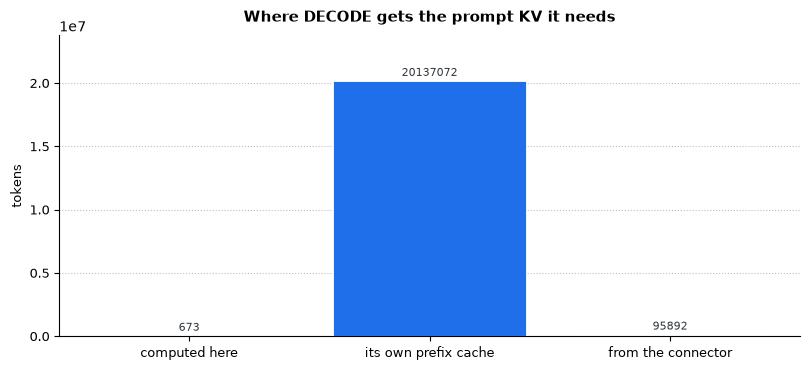

  how to read it: the first two are local to decode; only the third crossed between pods
  PASS  decode recomputes 0.0% of its prompt tokens

  >> Of 20,233,637 prompt tokens decode needed, 95,892 (0.5%) arrived as KV from prefill, 20,137,072 came from its own prefix cache, and it computed 673. The rest it had to compute itself.



Report(title='Dodona 02 — metrics', subtitle='what the numbers mean', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='What does each metric mean, what does good look like, and what can it NOT tell you?', note=''), _Block(kind='text', payload='Falsified by: a metric in the catalogue that no longer exists, or a trap that no longer reproduces', note=''), _Block(kind='heading', payload='0. Traffic for this run', note=''), _Block(kind='table', payload=(['', 'count'], [['requests sent', 12]]), note='Refusals here are gateway decisions, not GPU limits.'), _Block(kind='verdict', payload=(True, 'some traffic completed'), note=''), _Block(kind='conclusion', payload='12 requests, 0 refused. Every number below covers a 15-minute window that includes this traffic.', note=''), _Block(kind='heading', payload='Is the GPU busy?', note=''), _Block(kind='table', payload=(['metric', 'now', 'answers', 'means'], [['vllm:kv_cache_usage_perc', '0.1957', 'How full is 

In [7]:
report.heading('4.1 The KV connector')
# Scoped to decode. BOTH pools run a connector, so an unscoped sum counts
# prefill's queries too and credits prefill's own prompt work to decode —
# which made a perfect hop read as 'half of it was recomputed'.
D = '{pod=~"vllm-decode.*"}'
S = lambda src: ('sum(vllm:prompt_tokens_by_source_total'
                 f'{{source="{src}",pod=~"vllm-decode.*"}})')
asked    = v(f'sum(vllm:external_prefix_cache_queries_total{D})')
found    = v(f'sum(vllm:external_prefix_cache_hits_total{D})')
arrived  = v(S('external_kv_transfer'))
computed = v(S('local_compute'))
cached   = v(S('local_cache_hit'))

report.table(['stage', 'tokens', ''], [
    ['asked',   f'{asked:,.0f}',   'decode looked for blocks on the producer'],
    ['found',   f'{found:,.0f}',   'the lookup matched'],
    ['arrived', f'{arrived:,.0f}', 'KV that came over the wire'],
])
report.verdict(arrived > 0, 'the connector has delivered KV')
report.verdict(abs(found - arrived) < max(found, 1) * 0.1,
               'found and arrived agree — lookups are completing as transfers')

report.bar('Where DECODE gets the prompt KV it needs',
           ['computed here', 'its own prefix cache', 'from the connector'],
           {'prompt tokens': [computed, cached, arrived]}, ylabel='tokens',
           note='the first two are local to decode; only the third crossed between pods')

total = computed + cached + arrived
report.verdict(total == 0 or computed / total < 0.1,
               f'decode recomputes {computed/max(total,1):.1%} of its prompt tokens')
report.conclusion(
    f'Of {total:,.0f} prompt tokens decode needed, {arrived:,.0f} '
    f'({arrived/max(total,1):.1%}) arrived as KV from prefill, {cached:,.0f} came '
    f'from its own prefix cache, and it computed {computed:,.0f}. '
    + ('Decode does no prompt work at all — the hop is carrying the whole '
       'prompt, which is exactly what disaggregation is for.'
       if computed == 0 else 'The rest it had to compute itself.')
    if arrived > 0 else
    f'None of the {total:,.0f} prompt tokens came from the connector. '
    + (f'It was asked {asked:,.0f} times and found {found:,.0f}, so the lookup '
       'works and the transfer does not — check `make kv`.'
       if found > 0 else 'It found nothing, so there was nothing to transfer.'))


### 4.2 Prefill and decode are doing different jobs

The split is only real if the two pools behave differently. Prefill's leg is
sent with `max_tokens=1`: enough to build the prompt's KV, not to answer.
So prefill should emit **one token per request** and decode should do the
generating.


In [8]:
report.heading('4.2 Prefill and decode')
# Over ONE window, not raw totals. orch_requests_total resets when
# orch-serve restarts — which it does on every `make cluster` — while the
# vLLM pods are hours older. Dividing one by the other mixes two different
# time origins and reported 5.24 tokens per request for a max_tokens=1 leg.
W = '1h'
pre_gen = v(f'sum(increase(vllm:generation_tokens_total{{pod=~"vllm-prefill.*"}}[{W}]))')
dec_gen = v(f'sum(increase(vllm:generation_tokens_total{{pod=~"vllm-decode.*"}}[{W}]))')
pre_req = v(f'sum(increase(vllm:request_success_total{{pod=~"vllm-prefill.*"}}[{W}]))')
per_req = pre_gen / pre_req if pre_req else 0

report.table(['', f'last {W}', ''], [
    ['prefill requests',  f'{pre_req:,.0f}', 'its leg of each split'],
    ['prefill generated', f'{pre_gen:,.0f}', f'{per_req:.2f} tokens per request'],
    ['decode generated',  f'{dec_gen:,.0f}', 'the actual answers'],
], note='Both from the same window and the same pods, so the ratio is real.')
report.verdict(pre_req == 0 or per_req < 1.5,
               f'prefill emits {per_req:.2f} tokens per request (max_tokens=1 '
               'means ~1.0)')
report.conclusion(
    f'Over the last {W} prefill answered {pre_req:,.0f} requests with '
    f'{pre_gen:,.0f} tokens — {per_req:.2f} each, which is the max_tokens=1 leg '
    f'doing prompt work only, against decode\'s {dec_gen:,.0f}. The two pools '
    'are doing different jobs.'
    if per_req < 1.5 else
    f'Prefill emitted {per_req:.2f} tokens per request. A max_tokens=1 leg '
    'cannot do that, so both legs are sending the full request — check '
    'LAB_SPLIT and queue.py.')



4.2 Prefill and decode


                     last 1h                         
  -----------------  -------  -----------------------
  prefill requests     1,720  its leg of each split  
  prefill generated    1,720  1.00 tokens per request
  decode generated   323,416  the actual answers     
  -- Both from the same window and the same pods, so the ratio is real.
  PASS  prefill emits 1.00 tokens per request (max_tokens=1 means ~1.0)

  >> Over the last 1h prefill answered 1,720 requests with 1,720 tokens — 1.00 each, which is the max_tokens=1 leg doing prompt work only, against decode's 323,416. The two pools are doing different jobs.



Report(title='Dodona 02 — metrics', subtitle='what the numbers mean', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='What does each metric mean, what does good look like, and what can it NOT tell you?', note=''), _Block(kind='text', payload='Falsified by: a metric in the catalogue that no longer exists, or a trap that no longer reproduces', note=''), _Block(kind='heading', payload='0. Traffic for this run', note=''), _Block(kind='table', payload=(['', 'count'], [['requests sent', 12]]), note='Refusals here are gateway decisions, not GPU limits.'), _Block(kind='verdict', payload=(True, 'some traffic completed'), note=''), _Block(kind='conclusion', payload='12 requests, 0 refused. Every number below covers a 15-minute window that includes this traffic.', note=''), _Block(kind='heading', payload='Is the GPU busy?', note=''), _Block(kind='table', payload=(['metric', 'now', 'answers', 'means'], [['vllm:kv_cache_usage_perc', '0.1957', 'How full is 

### 4.3 The slice, not the card

`kv_cache_usage_perc` is a ratio of **one pod's own** KV. On this cluster each
pod has a 12 GiB HAMi slice, not the whole card — so the absolute numbers
differ by about 15x and only one of them is the right denominator.


In [9]:
report.heading('4.3 Slice capacity')
KV_GIB, SEQ_PER_POD = 4.10, 4.7
# The peak over an hour, not the instant. An idle reading makes the whole
# section a tautology: 0% of a slice is 0 GiB, which says nothing.
peak = v('max(max_over_time(vllm:kv_cache_usage_perc[1h]))')
now  = v('max(vllm:kv_cache_usage_perc)')

report.table(['', 'KV available', 'full-length sequences @16k'], [
    ['the whole H100', '~64 GiB', '~73.5'],
    ['one 12 GiB HAMi slice', f'{KV_GIB:.2f} GiB', f'{SEQ_PER_POD:.1f}'],
], note='CUDA-graph capture scales with available memory, so the whole-card '
        'figure cannot be divided down — it is measured per slice.')
report.table(['kv_cache_usage_perc', 'ratio', 'of this slice'], [
    ['now', f'{now:.1%}', f'{now*KV_GIB:.2f} GiB'],
    ['peak over 1h', f'{peak:.1%}', f'{peak*KV_GIB:.2f} GiB'],
])
report.verdict(peak < 0.90,
               f'KV peaked at {peak:.1%} — below the 0.90 admission threshold')
report.conclusion(
    f'A pod holds {KV_GIB:.2f} GiB of KV, which is {SEQ_PER_POD:.1f} full-length '
    f'sequences — that is the denominator for every concurrency claim, and it is '
    f'15x smaller than the whole card would suggest. Over the last hour KV peaked '
    f'at {peak:.1%} ({peak*KV_GIB:.2f} GiB), so '
    + ('the admission threshold was reachable.' if peak >= 0.90 else
       'a kv_threshold policy had nothing to decide. Making it bind is what '
       '03-capacity is for.'))



4.3 Slice capacity


                         KV available  full-length sequences @16k
  ---------------------  ------------  --------------------------
  the whole H100         ~64 GiB       ~73.5                     
  one 12 GiB HAMi slice  4.10 GiB      4.7                       
  -- CUDA-graph capture scales with available memory, so the whole-card figure cannot be divided down — it is measured per slice.
  kv_cache_usage_perc  ratio  of this slice
  -------------------  -----  -------------
  now                  19.6%       0.80 GiB
  peak over 1h         80.3%       3.29 GiB
  PASS  KV peaked at 80.3% — below the 0.90 admission threshold

  >> A pod holds 4.10 GiB of KV, which is 4.7 full-length sequences — that is the denominator for every concurrency claim, and it is 15x smaller than the whole card would suggest. Over the last hour KV peaked at 80.3% (3.29 GiB), so a kv_threshold policy had nothing to decide. Making it bind is what 03-capacity is for.



Report(title='Dodona 02 — metrics', subtitle='what the numbers mean', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='What does each metric mean, what does good look like, and what can it NOT tell you?', note=''), _Block(kind='text', payload='Falsified by: a metric in the catalogue that no longer exists, or a trap that no longer reproduces', note=''), _Block(kind='heading', payload='0. Traffic for this run', note=''), _Block(kind='table', payload=(['', 'count'], [['requests sent', 12]]), note='Refusals here are gateway decisions, not GPU limits.'), _Block(kind='verdict', payload=(True, 'some traffic completed'), note=''), _Block(kind='conclusion', payload='12 requests, 0 refused. Every number below covers a 15-minute window that includes this traffic.', note=''), _Block(kind='heading', payload='Is the GPU busy?', note=''), _Block(kind='table', payload=(['metric', 'now', 'answers', 'means'], [['vllm:kv_cache_usage_perc', '0.1957', 'How full is 

## 5. The same numbers, as Grafana draws them

Rendered server-side, not redrawn — a screenshot of the panel the team
already watches needs no explanation of how it was derived.

Needs `GRAFANA_PASSWORD` and the renderer deployment; falls back to links.


In [10]:
from pathlib import Path
shots = Path('screenshots'); shots.mkdir(exist_ok=True)
wanted = [('dodona-vllm', 'vllm', 'GPU KV cache'), ('dodona-vllm', 'vllm', 'TTFT'),
          ('dodona-mooncake', 'mooncake', 'DELIVERED'),
          ('dodona-mooncake', 'mooncake', 'Claimed vs delivered'),
          ('dodona-gateway', 'gateway', 'shed')]
saved = []
for uid, dash, title in wanted:
    pid = panel_id(dash, title)
    if pid is None: continue
    out = grafana.render(uid, pid, shots / f'{dash}-{title[:18].lower().replace(" ","-")}.png')
    if out: saved.append(out)

if saved:
    report.verdict(True, f'rendered {len(saved)} Grafana panels')
    from IPython.display import Image, display
    for s in saved: display(Image(filename=str(s)))
else:
    report.text('No panels rendered — set GRAFANA_PASSWORD (printed by '
                'make observability) and check renderer.yaml is deployed.')
    report.links([(d, f'{GRAFANA_URL}/d/{u}?from=now-30m&to=now')
                  for u, d in dict.fromkeys((u, d) for u, d, _ in wanted)])


  No panels rendered — set GRAFANA_PASSWORD (printed by make observability) and check renderer.yaml is deployed.


- [vllm](http://127.0.0.1:31495/d/dodona-vllm?from=now-30m&to=now)
- [mooncake](http://127.0.0.1:31495/d/dodona-mooncake?from=now-30m&to=now)
- [gateway](http://127.0.0.1:31495/d/dodona-gateway?from=now-30m&to=now)

## Save


In [11]:
fails = report.failures()
print()
if fails:
    for f in fails: print('  open:', f)
else:
    print('Every metric accounted for. Next: 03-capacity')



  open: SLO MISSED — TTFT p95: 2.32931s <= 0.8s
